✅ GMM Class Defined.
✅ Helper Functions Defined.

==================== PROCESSING: satellite_1.png ====================
Fitting GMM with k=3 for 100 iterations...
GMM fitting complete.
Generating static segmentation plot...


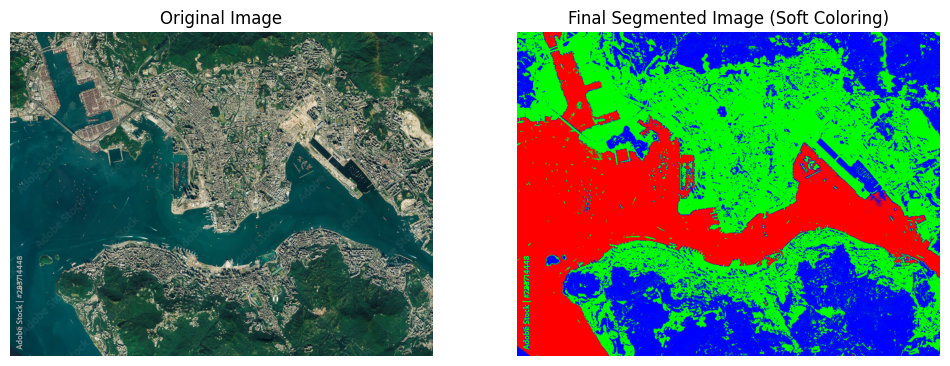

Generating animation video...
✅ Animation successfully saved as 'gmm_animation_satellite_1.mp4'

==================== PROCESSING: satellite_2.png ====================
Fitting GMM with k=3 for 100 iterations...
GMM fitting complete.
Generating static segmentation plot...


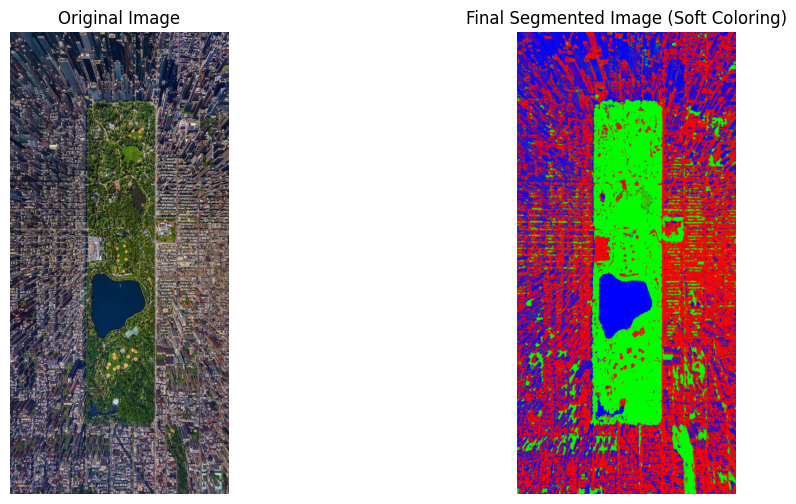

Generating animation video...
✅ Animation successfully saved as 'gmm_animation_satellite_2.mp4'

==================== ALL IMAGES PROCESSED ====================


In [35]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from PIL import Image
from sklearn.cluster import KMeans
from scipy.stats import multivariate_normal

# --- Step 1: Define the GMM Class (No changes needed here) ---
class MyGMM:
    """A from-scratch GMM that stores history for visualization."""
    def __init__(self, k, max_iters=100, tol=1e-4):
        self.k = k
        self.max_iters = max_iters
        self.tol = tol
        self.history_ = {
            'means': [], 'covariances': [], 'weights': [],
            'responsibilities': [], 'log_likelihood': []
        }
        self.weights_, self.means_, self.covariances_ = None, None, None

    def fit(self, X):
        n_samples, n_features = X.shape
        kmeans = KMeans(n_clusters=self.k, n_init=10, random_state=42).fit(X)
        self.means_ = kmeans.cluster_centers_
        self.covariances_ = np.array([np.eye(n_features)] * self.k)
        self.weights_ = np.ones(self.k) / self.k

        for i in range(self.max_iters):
            responsibilities = self._calculate_responsibilities(X)
            nk = np.sum(responsibilities, axis=0)
            self.weights_ = nk / n_samples
            self.means_ = (responsibilities.T @ X) / nk[:, np.newaxis]
            for j in range(self.k):
                diff = X - self.means_[j]
                self.covariances_[j] = (responsibilities[:, j, np.newaxis] * diff).T @ diff / nk[j]
            log_likelihood = self._get_log_likelihood(X)
            self.history_['means'].append(self.means_.copy())
            self.history_['covariances'].append(self.covariances_.copy())
            self.history_['weights'].append(self.weights_.copy())
            self.history_['responsibilities'].append(responsibilities.copy())
            self.history_['log_likelihood'].append(log_likelihood)
            if i > 0 and abs(self.history_['log_likelihood'][-1] - self.history_['log_likelihood'][-2]) < self.tol:
                break
        return self

    def _calculate_responsibilities(self, X):
        likelihoods = np.zeros((X.shape[0], self.k))
        for i in range(self.k):
            dist = multivariate_normal(self.means_[i], self.covariances_[i], allow_singular=True)
            likelihoods[:, i] = dist.pdf(X)
        numerator = likelihoods * self.weights_
        denominator = np.sum(numerator, axis=1, keepdims=True)
        denominator[denominator == 0] = 1e-20
        return numerator / denominator

    def _get_log_likelihood(self, X):
        likelihoods = np.zeros((X.shape[0], self.k))
        for i in range(self.k):
            dist = multivariate_normal(self.means_[i], self.covariances_[i], allow_singular=True)
            likelihoods[:, i] = dist.pdf(X)
        return np.sum(np.log(np.sum(likelihoods * self.weights_, axis=1)))

print("✅ GMM Class Defined.")

# --- Step 2: Define Reusable Helper Functions ---

def prepare_image_data(filepath):
    """Loads, reshapes, and normalizes image data."""
    try:
        img = Image.open(filepath)
        img_array = np.array(img)
        h, w, _ = img_array.shape
        pixel_data = img_array.reshape(-1, 3) / 255.0
        return pixel_data, (h, w), img
    except FileNotFoundError:
        print(f"❌ Error: The file '{filepath}' was not found.")
        return None, None, None

def create_static_segmentation(gmm_model, original_image, image_shape, colors):
    """Creates and displays a final segmented image using soft coloring."""
    height, width = image_shape
    final_responsibilities = gmm_model.history_['responsibilities'][-1]
    segmented_data = np.dot(final_responsibilities, colors)
    segmented_image = segmented_data.reshape(height, width, 3)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].imshow(original_image)
    axes[0].set_title('Original Image')
    axes[0].axis('off')
    axes[1].imshow(segmented_image)
    axes[1].set_title('Final Segmented Image (Soft Coloring)')
    axes[1].axis('off')
    plt.show()

def create_gmm_animation(gmm_model, original_image, image_shape, colors, output_filename):
    """Creates and saves the 3-panel GMM progress animation."""
    height, width = image_shape
    num_frames = len(gmm_model.history_['means'])

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle('GMM Image Segmentation: EM Algorithm Progression', fontsize=16)

    axes[0].imshow(original_image); axes[0].set_title('Original'); axes[0].axis('off')
    segmented_artist = axes[1].imshow(np.zeros((height, width, 3)))
    axes[1].set_title('Segmented (Iteration 1)'); axes[1].axis('off')
    line, = axes[2].plot([], [], 'o-'); axes[2].set_title('Log-Likelihood')
    axes[2].grid(True); axes[2].set_xlabel('Iteration'); axes[2].set_ylabel('Log-Likelihood')
    min_ll, max_ll = np.min(gmm_model.history_['log_likelihood']), np.max(gmm_model.history_['log_likelihood'])
    axes[2].set_xlim(0, num_frames); axes[2].set_ylim(min_ll - abs(min_ll) * 0.1, max_ll + abs(max_ll) * 0.1)

    def update(i):
        responsibilities = gmm_model.history_['responsibilities'][i]
        segmented_data = np.dot(responsibilities, colors)
        segmented_artist.set_data(segmented_data.reshape(height, width, 3))
        axes[1].set_title(f'Segmented (Iteration {i+1})')
        log_likelihood_slice = gmm_model.history_['log_likelihood'][:i+1]
        line.set_data(range(1, len(log_likelihood_slice) + 1), log_likelihood_slice)
        return [segmented_artist, line]

    ani = FuncAnimation(fig, update, frames=num_frames, interval=500, blit=True)
    try:
        ani.save(output_filename, writer='ffmpeg', dpi=100)
        print(f"✅ Animation successfully saved as '{output_filename}'")
    except Exception as e:
        print(f"❌ Error saving animation for '{output_filename}': {e}")
        print("   Please make sure 'ffmpeg' is installed on your system.")
    plt.close(fig) # Close the figure to prevent it from displaying statically

print("✅ Helper Functions Defined.")

# --- Step 3: Main Execution Loop ---

# Define constants and the list of images to process
IMAGE_FILES = ['satellite_1.png', 'satellite_2.png']
CONTRASTING_COLORS = np.array([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]], dtype=float)
K_CLUSTERS = 3
MAX_ITERATIONS = 100

# Loop through each image file and perform the full analysis
for filename in IMAGE_FILES:
    print(f"\n{'='*20} PROCESSING: {filename} {'='*20}")

    # 1. Prepare the data for the current image
    pixel_data, shape, original_img = prepare_image_data(filename)

    if pixel_data is not None:
        # 2. Fit a new GMM instance to this image's data
        print(f"Fitting GMM with k={K_CLUSTERS} for {MAX_ITERATIONS} iterations...")
        gmm_model = MyGMM(k=K_CLUSTERS, max_iters=MAX_ITERATIONS)
        gmm_model.fit(pixel_data)
        print("GMM fitting complete.")

        # 3. Create and show the final static segmented image
        print("Generating static segmentation plot...")
        create_static_segmentation(gmm_model, original_img, shape, CONTRASTING_COLORS)

        # 4. Create and save the dynamic animation video
        print("Generating animation video...")
        video_filename = f"gmm_animation_{filename.replace('.png', '.mp4')}"
        create_gmm_animation(gmm_model, original_img, shape, CONTRASTING_COLORS, video_filename)

print(f"\n{'='*20} ALL IMAGES PROCESSED {'='*20}")


* One Drive videos link - https://iiithydstudents-my.sharepoint.com/:f:/g/personal/bhogadi_likhit_students_iiit_ac_in/EoeJ3_zIFn5PjzrJw2l36yoBB_IFHxWm6h40ZIF6guiGcg?e=twktat